<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/3_5_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[BASARILI] 5x5 Medyan filtreleme islemleri (Hazir ve Manuel) tamamlandi.


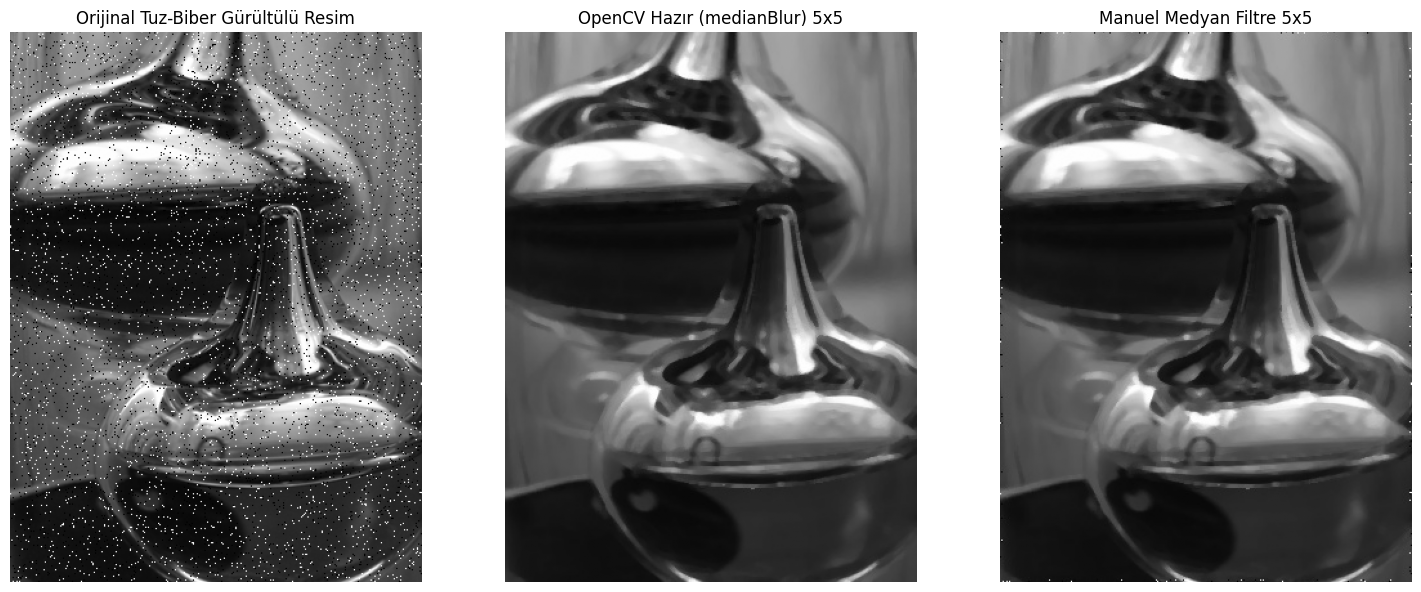

In [ ]:
# 1. OpenCV C++ Kütüphanelerini Kur
!apt-get install libopencv-dev -y > /dev/null 2>&1

# 2. C++ Dosyasını Derle ve Çalıştır
!g++ -o odev5 odev_h3_g5.cpp `pkg-config --cflags --libs opencv4`
!./odev5

# 3. Sonuçları Ekranda Görselleştir
import cv2
import matplotlib.pyplot as plt

# Çıktıları Oku
img_noisy = cv2.imread('noisy_image.jpg', cv2.IMREAD_GRAYSCALE)
img_cv = cv2.imread('G5_cv_median.jpg', cv2.IMREAD_GRAYSCALE)
img_man = cv2.imread('G5_manuel_median.jpg', cv2.IMREAD_GRAYSCALE)

if img_noisy is not None:
    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.title('Orijinal Tuz-Biber Gürültülü Resim')
    plt.imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title('OpenCV Hazır (medianBlur) 5x5')
    plt.imshow(img_cv, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title('Manuel Medyan Filtre 5x5')
    plt.imshow(img_man, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

[BASARILI] 5x5 Medyan filtreleme islemleri (Hazir ve Manuel) tamamlandi.


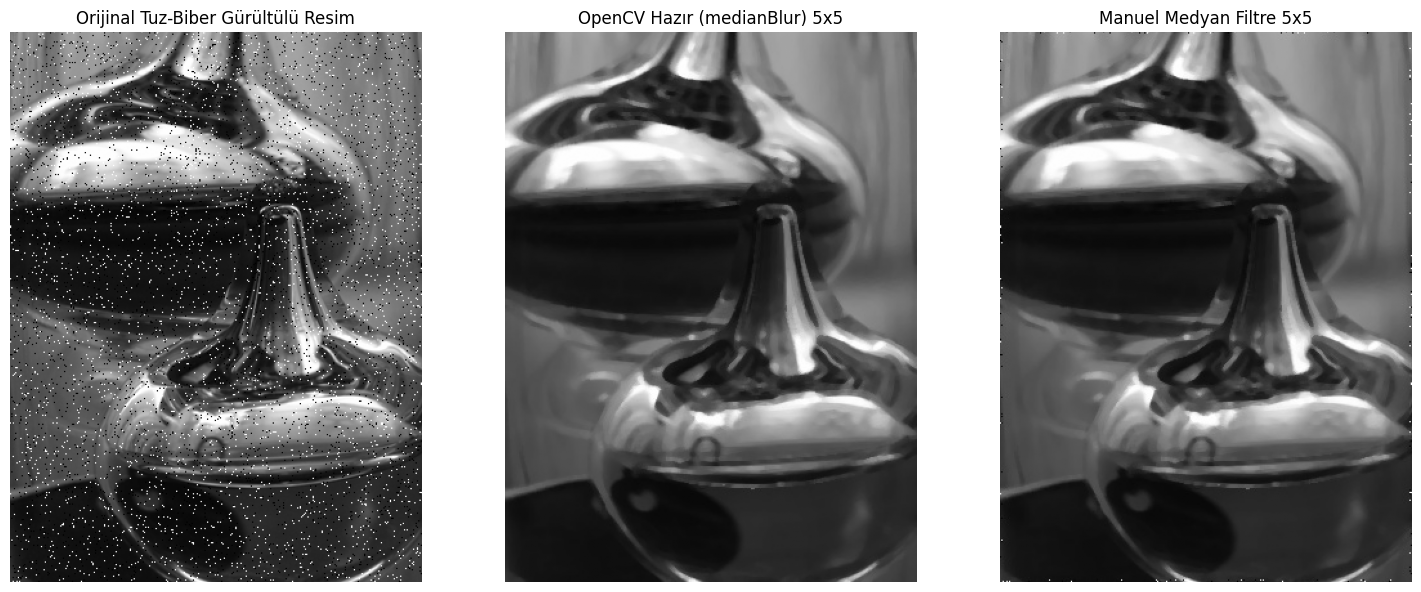

In [ ]:
# 1. OpenCV C++ Kütüphanelerini Kur
!apt-get install libopencv-dev -y > /dev/null 2>&1

# 2. C++ Dosyasını Derle ve Çalıştır
!g++ -o odev5 odev_h3_g5.cpp `pkg-config --cflags --libs opencv4`
!./odev5

# 3. Sonuçları Ekranda Görselleştir
import cv2
import matplotlib.pyplot as plt

# Çıktıları Oku
img_noisy = cv2.imread('noisy_image.jpg', cv2.IMREAD_GRAYSCALE)
img_cv = cv2.imread('G5_cv_median.jpg', cv2.IMREAD_GRAYSCALE)
img_man = cv2.imread('G5_manuel_median.jpg', cv2.IMREAD_GRAYSCALE)

if img_noisy is not None:
    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.title('Orijinal Tuz-Biber Gürültülü Resim')
    plt.imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title('OpenCV Hazır (medianBlur) 5x5')
    plt.imshow(img_cv, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title('Manuel Medyan Filtre 5x5')
    plt.imshow(img_man, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
%%writefile odev_h3_g5.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <algorithm> // sort fonksiyonu için gerekli

using namespace cv;
using namespace std;

// ==============================================================================
// MANUEL 5x5 MEDYAN FİLTRESİ
// ==============================================================================
void medianFilterManuel5x5(const Mat& src, Mat& dst) {
    dst = src.clone();
    int kSize = 5;
    int border = kSize / 2; // 5x5 için kenar boşluğu = 2 piksel

    // Görüntüyü tarıyoruz (Kenarlarda taşma olmaması için sınırları daraltıyoruz)
    for (int r = border; r < src.rows - border; ++r) {
        for (int c = border; c < src.cols - border; ++c) {

            // 5x5'lik penceredeki pikselleri toplayacağımız vektör
            vector<uchar> neighborhood;
            neighborhood.reserve(25);

            // 5x5 pencere (kernel) içinde gez
            for (int i = -border; i <= border; ++i) {
                for (int j = -border; j <= border; ++j) {
                    neighborhood.push_back(src.at<uchar>(r + i, c + j));
                }
            }

            // Vektörü küçükten büyüğe sırala
            sort(neighborhood.begin(), neighborhood.end());

            // 25 elemanlı sıralı dizinin tam ortasındaki eleman (Medyan) 12. indekstir.
            dst.at<uchar>(r, c) = neighborhood[12];
        }
    }
}

int main() {
    // 1. Gürültülü Görüntüyü Oku
    Mat img_noisy = imread("noisy_image.jpg", IMREAD_GRAYSCALE);
    if (img_noisy.empty()) {
        cout << "[HATA] Gorsel bulunamadi! Lutfen 'noisy_image.jpg' adinda tuz-biber gurultulu bir resim yukleyin." << endl;
        return -1;
    }

    // 2. Hazır Fonksiyon ile Medyan Filtresi (OpenCV medianBlur)
    Mat img_cv_median;
    medianBlur(img_noisy, img_cv_median, 5); // 5x5 pencere
    imwrite("G5_cv_median.jpg", img_cv_median);

    // 3. Manuel (Kendi Yazdığımız) 5x5 Medyan Filtresi
    Mat img_manuel_median;
    medianFilterManuel5x5(img_noisy, img_manuel_median);
    imwrite("G5_manuel_median.jpg", img_manuel_median);

    cout << "[BASARILI] 5x5 Medyan filtreleme islemleri (Hazir ve Manuel) tamamlandi." << endl;
    return 0;
}

Overwriting odev_h3_g5.cpp


[BASARILI] 5x5 Medyan filtreleme islemleri (Hazir ve Manuel) tamamlandi.


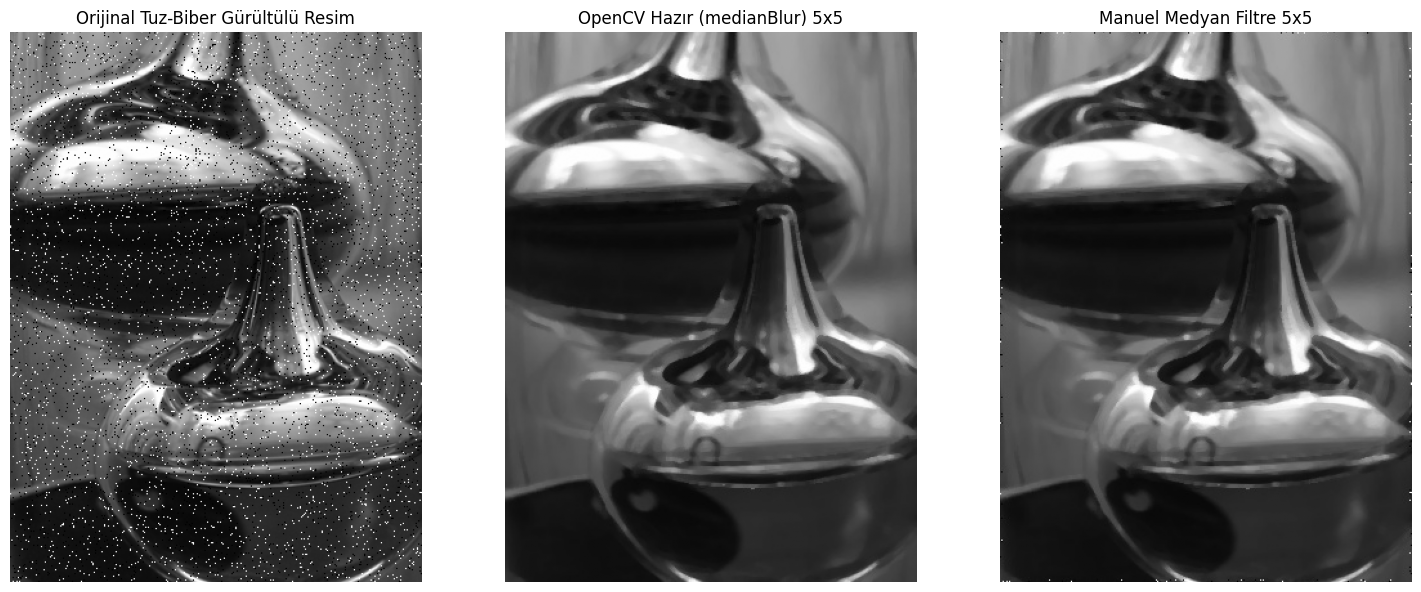

In [ ]:
# 1. OpenCV C++ Kütüphanelerini Kur
!apt-get install libopencv-dev -y > /dev/null 2>&1

# 2. C++ Dosyasını Derle ve Çalıştır
!g++ -o odev5 odev_h3_g5.cpp `pkg-config --cflags --libs opencv4`
!./odev5

# 3. Sonuçları Ekranda Görselleştir
import cv2
import matplotlib.pyplot as plt

# Çıktıları Oku
img_noisy = cv2.imread('noisy_image.jpg', cv2.IMREAD_GRAYSCALE)
img_cv = cv2.imread('G5_cv_median.jpg', cv2.IMREAD_GRAYSCALE)
img_man = cv2.imread('G5_manuel_median.jpg', cv2.IMREAD_GRAYSCALE)

if img_noisy is not None:
    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.title('Orijinal Tuz-Biber Gürültülü Resim')
    plt.imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title('OpenCV Hazır (medianBlur) 5x5')
    plt.imshow(img_cv, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title('Manuel Medyan Filtre 5x5')
    plt.imshow(img_man, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.tight_layout()
    plt.show()